In [ ]:


from google.colab import files
uploaded = files.upload()

Saving Tweets.csv to Tweets.csv


In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from nltk.corpus import stopwords
import nltk

nltk.download("stopwords")

print("All libraries imported successfully.")

All libraries imported successfully.


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:

df = pd.read_csv("Tweets.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (14640, 15)

Column names:
['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [ ]:

required_columns = ["text", "airline_sentiment"]

for col in required_columns:
    if col not in df.columns:
        raise ValueError(
            f"Missing column: {col}. "
            f"Available columns: {df.columns.tolist()}"
        )

df = df[required_columns].copy()
df.columns = ["text", "sentiment"]

df = df.dropna(subset=["text", "sentiment"])
df["text"] = df["text"].astype(str)
df["sentiment"] = df["sentiment"].astype(str).str.lower()

df = df[df["sentiment"].isin(
    ["positive", "negative", "neutral"]
)]

df = df.drop_duplicates().reset_index(drop=True)

print("Number of documents after cleaning:", len(df))
print("\nClass counts:")
print(df["sentiment"].value_counts())

print("\nClass percentages:")
print(
    (df["sentiment"].value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + "%"
)

Number of documents after cleaning: 14452

Class counts:
sentiment
negative    9087
neutral     3067
positive    2298
Name: count, dtype: int64

Class percentages:
sentiment
negative    62.88%
neutral     21.22%
positive     15.9%
Name: proportion, dtype: object


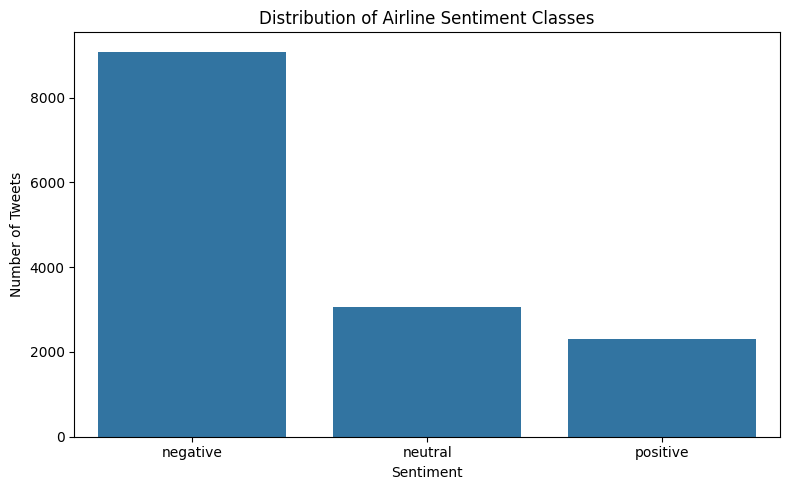

In [ ]:


plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sentiment",
    order=["negative", "neutral", "positive"]
)

plt.title("Distribution of Airline Sentiment Classes")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.tight_layout()
plt.show()

In [ ]:


from nltk.stem import PorterStemmer

stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

def preprocess_text(text):
    text = str(text).lower()

    # Remove URLs and email addresses
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)

    # Remove Twitter usernames
    text = re.sub(r"@\w+", " ", text)

    # Preserve hashtag words
    text = re.sub(r"#(\w+)", r"\1", text)

    # Remove numbers and punctuation
    text = re.sub(r"[^a-z\s]", " ", text)

    tokens = text.split()

    tokens = [
        stemmer.stem(word)
        for word in tokens
        if word not in stop_words and len(word) > 1
    ]

    return " ".join(tokens)

df["processed_text"] = df["text"].apply(preprocess_text)

display(df[["text", "processed_text", "sentiment"]].head())

,text,processed_text,sentiment
0,@VirginAmerica What @dhepburn said.,said,neutral
1,@VirginAmerica plus you've added commercials t...,plu ad commerci experi tacki,positive
2,@VirginAmerica I didn't today... Must mean I n...,today must mean need take anoth trip,neutral
3,@VirginAmerica it's really aggressive to blast...,realli aggress blast obnoxi entertain guest fa...,negative
4,@VirginAmerica and it's a really big bad thing...,realli big bad thing,negative


In [ ]:

X = df["processed_text"]
y = df["sentiment"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train_text))
print("Testing samples:", len(X_test_text))

Training samples: 11561
Testing samples: 2891


In [ ]:

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=2
)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Training matrix:", X_train.shape)
print("Testing matrix:", X_test.shape)
print("Number of features:", len(tfidf.get_feature_names_out()))

Training matrix: (11561, 10000)
Testing matrix: (2891, 10000)
Number of features: 10000


In [ ]:


models = {
    "Decision Tree": DecisionTreeClassifier(
        criterion="gini",
        class_weight="balanced",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    ),

    "SVM": LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=10000
    ),

    "Naive Bayes": MultinomialNB(
        alpha=1.0
    )
}

print("All four classifiers are defined.")

All four classifiers are defined.


In [ ]:


results = []
predictions = {}
trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    start_train = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start_train

    start_test = time.perf_counter()
    y_pred = model.predict(X_test)
    test_time = time.perf_counter() - start_test

    predictions[name] = y_pred
    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),

        "Macro Precision": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        ),

        "Training Time (s)": train_time,
        "Testing Time (s)": test_time
    })

    print(f"{name} completed.")

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

Training Decision Tree...
Decision Tree completed.
Training KNN...
KNN completed.
Training SVM...
SVM completed.
Training Naive Bayes...
Naive Bayes completed.


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Training Time (s),Testing Time (s)
0,SVM,0.7558,0.6878,0.6872,0.6875,0.7551,0.2607,0.0012
1,Decision Tree,0.6666,0.5895,0.6108,0.5985,0.6729,7.6245,0.0027
2,KNN,0.6832,0.6082,0.5735,0.5866,0.6787,0.0235,1.4054
3,Naive Bayes,0.7108,0.7742,0.4955,0.5257,0.6510,0.0411,0.0009


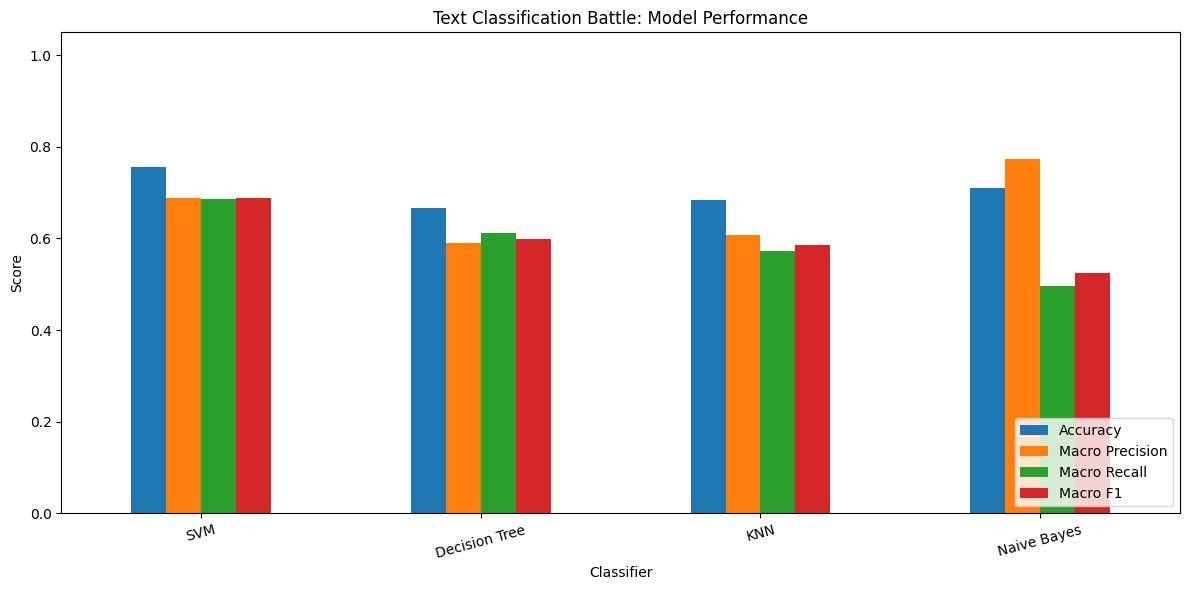

In [ ]:


metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

ax = results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Text Classification Battle: Model Performance")
ax.set_ylabel("Score")
ax.set_xlabel("Classifier")
ax.set_ylim(0, 1.05)

plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

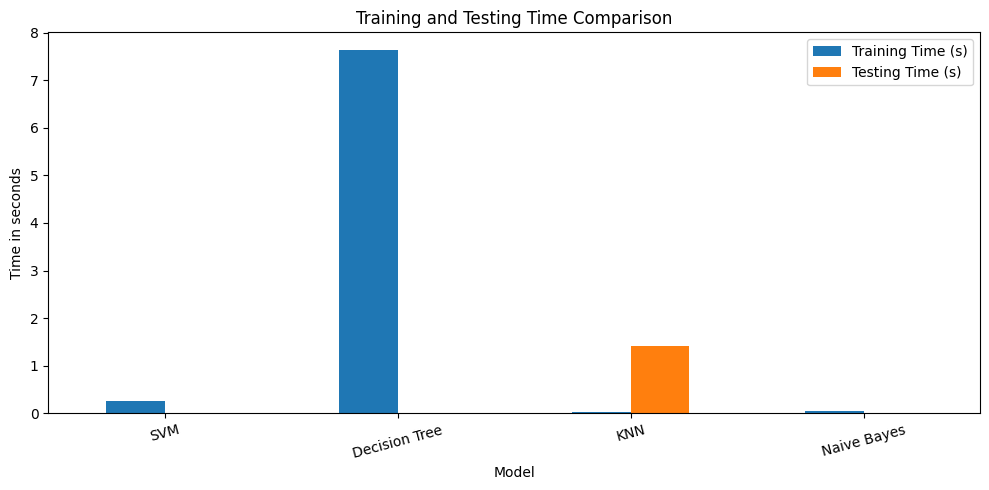

In [ ]:


time_columns = ["Training Time (s)", "Testing Time (s)"]

results_df.set_index("Model")[time_columns].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Training and Testing Time Comparison")
plt.ylabel("Time in seconds")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:


for name, pred in predictions.items():
    print("\n" + "=" * 60)
    print("CLASSIFIER:", name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            pred,
            labels=["negative", "neutral", "positive"],
            zero_division=0,
            digits=4
        )
    )


CLASSIFIER: Decision Tree
              precision    recall  f1-score   support

    negative     0.8036    0.7426    0.7719      1818
     neutral     0.4391    0.4943    0.4651       613
    positive     0.5259    0.5957    0.5586       460

    accuracy                         0.6666      2891
   macro avg     0.5895    0.6108    0.5985      2891
weighted avg     0.6821    0.6666    0.6729      2891


CLASSIFIER: KNN
              precision    recall  f1-score   support

    negative     0.7789    0.8218    0.7998      1818
     neutral     0.4281    0.4421    0.4350       613
    positive     0.6176    0.4565    0.5250       460

    accuracy                         0.6832      2891
   macro avg     0.6082    0.5735    0.5866      2891
weighted avg     0.6789    0.6832    0.6787      2891


CLASSIFIER: SVM
              precision    recall  f1-score   support

    negative     0.8453    0.8504    0.8478      1818
     neutral     0.5494    0.5351    0.5421       613
    positive  

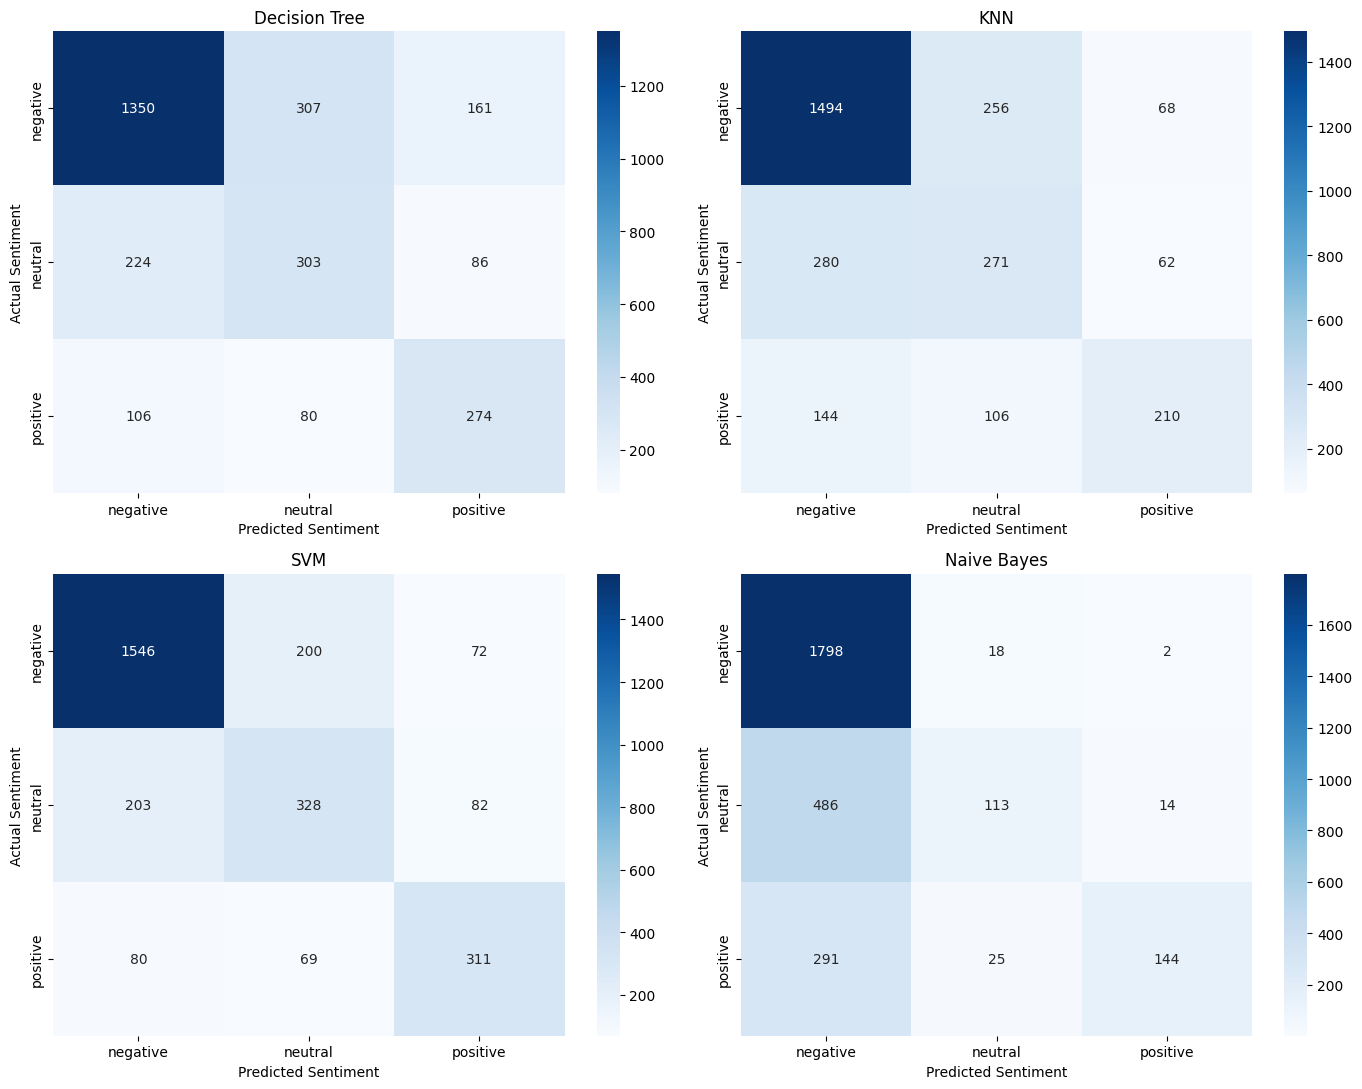

In [ ]:


labels = ["negative", "neutral", "positive"]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, (name, pred) in zip(axes.ravel(), predictions.items()):

    cm = confusion_matrix(
        y_test,
        pred,
        labels=labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Sentiment")
    ax.set_ylabel("Actual Sentiment")

plt.tight_layout()
plt.show()

Best classifier: SVM

Best model performance:
Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1  Training Time (s)  Testing Time (s)
  SVM  0.755794         0.687834      0.687182  0.687467       0.7551           0.260695          0.001235


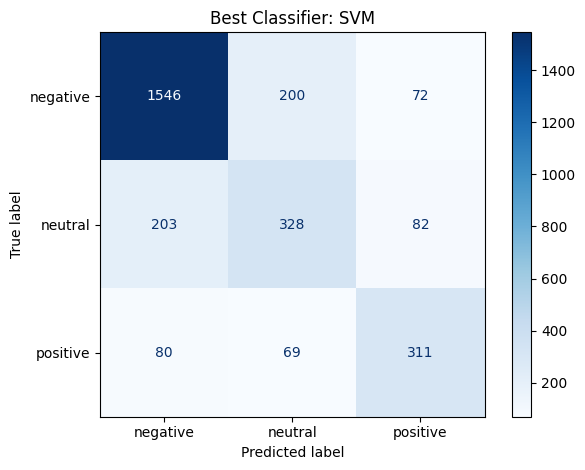

In [ ]:


best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]
best_pred = predictions[best_name]

print("Best classifier:", best_name)

print("\nBest model performance:")
print(
    results_df.loc[
        results_df["Model"] == best_name
    ].to_string(index=False)
)

cm = confusion_matrix(
    y_test,
    best_pred,
    labels=labels
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(cmap="Blues", values_format="d")

plt.title(f"Best Classifier: {best_name}")
plt.tight_layout()
plt.show()

In [ ]:


knn_results = []

for k in [1, 3, 5, 7, 11, 15]:

    model = KNeighborsClassifier(
        n_neighbors=k,
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    )

    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start

    pred = model.predict(X_test)

    knn_results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, pred),

        "Macro F1": f1_score(
            y_test, pred,
            average="macro",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            y_test, pred,
            average="weighted",
            zero_division=0
        ),

        "Training Time (s)": train_time
    })

knn_df = pd.DataFrame(knn_results)
display(knn_df.round(4))

,K,Accuracy,Macro F1,Weighted F1,Training Time (s)
0,1,0.5946,0.5315,0.6114,0.0704
1,3,0.6631,0.5750,0.6632,0.0299
2,5,0.6832,0.5866,0.6787,0.0295
3,7,0.6984,0.5990,0.6898,0.0471
4,11,0.7229,0.6204,0.7080,0.1249
5,15,0.7226,0.6122,0.7029,0.0179


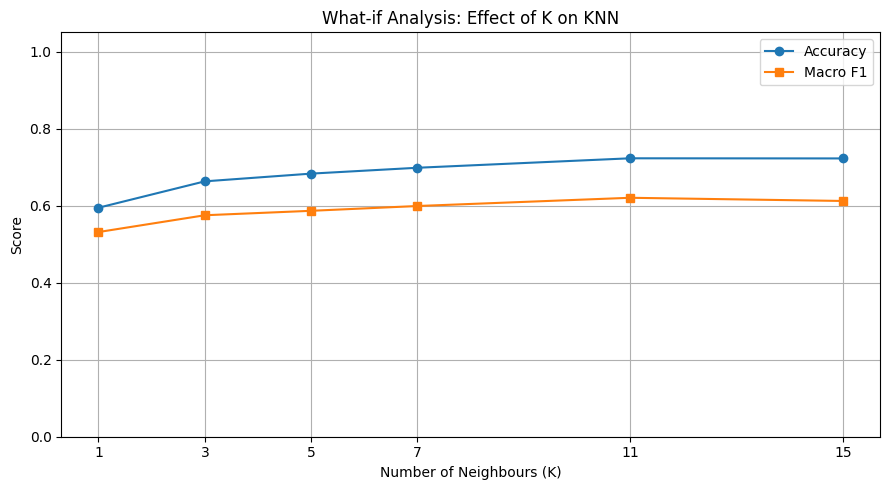

Best K by macro F1: 11
K                    11.000000
Accuracy              0.722933
Macro F1              0.620420
Weighted F1           0.707956
Training Time (s)     0.124934
Name: 4, dtype: float64


In [ ]:


plt.figure(figsize=(9, 5))

plt.plot(
    knn_df["K"],
    knn_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    knn_df["K"],
    knn_df["Macro F1"],
    marker="s",
    label="Macro F1"
)

plt.xlabel("Number of Neighbours (K)")
plt.ylabel("Score")
plt.title("What-if Analysis: Effect of K on KNN")
plt.xticks(knn_df["K"])
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

best_k_row = knn_df.loc[knn_df["Macro F1"].idxmax()]

print("Best K by macro F1:", int(best_k_row["K"]))
print(best_k_row)

In [ ]:


results_df.to_csv(
    "classifier_comparison.csv",
    index=False
)

knn_df.to_csv(
    "knn_what_if_results.csv",
    index=False
)

# Save a combined classification report
reports = []

for name, pred in predictions.items():
    report = classification_report(
        y_test,
        pred,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()
    report_df["Model"] = name
    reports.append(report_df.reset_index(names="Class"))

all_reports = pd.concat(reports, ignore_index=True)
all_reports.to_csv("classification_reports.csv", index=False)

print("All result files have been created.")

from google.colab import files

files.download("classifier_comparison.csv")
files.download("knn_what_if_results.csv")
files.download("classification_reports.csv")

All result files have been created.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>